<a href="https://colab.research.google.com/github/Nyanta432/Dinh_vi_cuon_vi_sai/blob/main/Cuon_vi_sai(t%E1%BB%AB_tr%C6%B0%E1%BB%9Dng_t%E1%BA%A1i_t%C3%A2m).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> ### 🔧 PHIÊN BẢN CẢI TIẾN (chỉ thay đổi 3 chỗ, mọi tính năng cũ giữ nguyên)
> 1. **Section 1:** dùng bộ `TX_positions` có **z ≈ 0.05 m** (bộ đã comment trước đây). Bộ cũ z = 0.1935 m bị comment lại (không xoá).
> 2. **Section 3:** forward model tính từ trường **tại tâm viên nang** (không trừ hai điểm). Bản vi sai hai điểm cũ được comment lại. Tên hàm `forwardModelvisai_dio` giữ nguyên nên Section 5 chạy không cần sửa. Thêm hàm vector hoá `emf_center_batch` (cùng công thức, chạy nhanh).
> 3. **Section 4:** vẫn là phương pháp **độ lệch (deviation)** và in ra đúng các dòng cũ (Độ lệch, Vector K, bảng `x_opt_all`), nhưng: chỉ cho **roll/pitch** lệch tối đa ±3.5° (yaw cố định) nên **hướng trục lệch ≤ ~5°**; K được **giải dạng đóng** (không còn khởi tạo K lệch); có **multi-start**. Thêm 1 dòng in "Hướng trục lệch so với cơ khí".
>
> 4. **(v2)** Section 4 cho phép lệch vị trí ±3 cm và dùng **trọng số cân bằng** `1/(|EMF đo| + EPS_W)` (EPS_W = 1.0) để cận trường không lấn át xa trường.
>
> 5. **(v3 - sửa lệch RX2)** Phân tích từng cuộn thu cho thấy **RX1 và RX3 khớp mô hình đơn (tâm viên nang, r⁻³)**, còn **RX2 khớp mô hình vi sai hai điểm (r⁻⁴)** (phần gradient chiếm 2–15 lần phần đơn khi fit hỗn hợp; RX1/RX3 chỉ 0–8%). Nên forward model chọn theo từng cuộn qua `sys.RX_MODE = ['center','diff','center']`; RX2 dùng `d_diff_rx[1]` = 1.6 mm. Section 4 chỉ đổi lời gọi `emf_center_batch` thành `emf_rx_batch`.

6. **(v4 - sửa lệch TX1/TX3)** Fit riêng từng TX cho thấy lỗi còn lại của TX1, TX3 không do nhiễu (hai file đo lặp lại tốt ở RX2/RX3, tương quan ≥ 0.99), không do ghép từ giữa các TX, không do nhiễu sàn, không do pose TX (nới biên vẫn kẹt). Thứ giải thích được là **viên nang thực tế bị xoay cố định so với hệ GT** (chung cho cả 3 TX và 3 RX). Thêm `sys.cap_rot = [roll, pitch, yaw]` (độ), ước lượng chung trong Section 4 (bước 0) rồi giữ cố định. Đặt `USE_CAP_ROT = False` để quay về v3.

Section 2 và Section 5 **không đổi**.

---

# HỆ THỐNG ĐỊNH VỊ TỪ TRƯỜNG 6-DOF (TỪ MATLAB SANG PYTHON)
**Bảo toàn bản chất Vi sai Không gian (Spatial Gradiometer) - Triệt tiêu Điểm kỳ dị**

## 1. Mô tả bài toán
Dự án yêu cầu giải mã tọa độ và góc quay 6-DOF (x, y, z, roll, pitch, yaw) của một viên nang nội soi chứa cuộn thu từ tính (RX) di chuyển trong trường điện từ tạo ra bởi 3 cuộn phát (TX).
Phần cứng RX được thiết kế dạng **Cuộn vi sai** (hai nửa quấn ngược chiều, cách nhau 0.25mm) nhằm chống nhiễu đồng pha.

## 2. Vấn đề gặp phải
* **Sự sụp đổ của thuật toán tại vùng Near-field:** Đặc tính vi sai khiến cường độ từ trường suy giảm theo tỷ lệ $1/r^4$. Khi viên nang tiến quá sát cuộn phát ($r \to 0$), mô hình lý thuyết bùng nổ lên vô cực (Singularity), khiến thuật toán tối ưu hoảng loạn và cho ra quỹ đạo sai lệch hoàn toàn.
* **Bẫy Gradient (Mù tỷ lệ):** Sự chênh lệch tỷ lệ khổng lồ giữa các biến số (Tọa độ $\sim 0.5$, Góc $\sim 180$, Hệ số bù trừ $K \sim 0.001$) khiến các bộ giải Python (`scipy`) mặc định bị kẹt ở cực tiểu cục bộ (Local Minima).

## 3. Giải pháp cốt lõi
1. **Điều chuẩn từ cực (Regularized Dipole Model):** Thay vì giả lập thành cuộn đơn, hệ thống giữ nguyên mô hình vi sai nhưng chèn thêm **bình phương bán kính cuộn phát ($R^2$)** vào mẫu số. Công thức $(r^2 + R^2)^{5/2}$ đóng vai trò là "hệ số chặn vật lý", giúp giữ từ trường hữu hạn khi $r \to 0$ mà vẫn giữ nguyên đặc tính vi sai.
2. **Cân bằng Jacobian tự động:** Áp dụng tham số `x_scale='jac'` trong `least_squares` để mô phỏng sự thông minh của hàm `lsqnonlin` (MATLAB), giúp thuật toán đánh giá công bằng bước nhảy của các biến số khác hệ quy chiếu.

# **Section 1: Cấu hình thông số vật lý, nạp và tách dữ liệu**

In [ ]:
# ==============================================================================
# SECTION 1: CẤU HÌNH THÔNG SỐ VẬT LÝ, NẠP VÀ TRÍCH XUẤT DỮ LIỆU
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import time
import os
import copy

class SystemConfig:
    """Lớp chứa hằng số vật lý của phần cứng (Hardware Specifications)"""
    def __init__(self):
        # 1. THÔNG SỐ CUỘN PHÁT (TX - Transmitter)
        self.Ntx = 300              # Số vòng dây cuộn phát
        self.R = 0.06               # Bán kính cuộn phát (m) -> Giúp chặn singularity
        self.I = np.array([1.0, 1.0, 1.0])  # Dòng điện 3 cuộn (Ampe)
        self.f = np.array([5053, 6911, 5932]) # Tần số 3 cuộn (Hz)

        # Tọa độ cơ khí ban đầu (Mồi): [x, y, z, roll, pitch, yaw] của 3 cuộn TX
        # (BỘ CƠ KHÍ CŨ, z = 0.1935 m - tạm tắt)
        # self.TX_positions = np.array([
        #     [0.35146, 0.61931, 0.19348, 15,   0,   0],  # TX1
        #     [0.42173, 0.51066, 0.19350,  0, -15, -30],  # TX2
        #     [0.29150, 0.51068, 0.19350,  0,  15,  30]   # TX3
        # ]).T

        # BỘ ĐANG DÙNG (z ≈ 0.05 m)
        self.TX_positions = np.array([
            [ 0.36029,  0.62473, 0.05577, 15 ,  0   , 0],  # TX1
            [ 0.43558,  0.50973, 0.05449,  0 ,  -15  , -30],  # TX2
            [ 0.29690,  0.50518, 0.04992, 0  ,  15  , 30]   # TX3
        ]).T

        # 2. THÔNG SỐ CUỘN THU (RX - Capsule)
        self.Nrx = 100              # Số vòng dây mỗi nửa cuộn vi sai
        self.d_diff = 1.5e-3
        #self.d_diff = 0.25e-3       # Khoảng cách vi sai (0.25 mm)
        # (v3) Khoảng cách vi sai từng cuộn (RX1, RX2, RX3) và mô hình dùng cho từng cuộn:
        #   'center' = từ trường tại tâm viên nang (r^-3);  'diff' = hiệu hai điểm B(r+)-B(r-) (r^-4)
        self.d_diff_rx = np.array([1.5e-3, 1.6e-3, 1.53e-3])
        self.RX_MODE = ['center', 'diff', 'center']
        # (v4) Xoay CỐ ĐỊNH của khung viên nang so với hệ GT (roll, pitch, yaw - độ). Chung cho cả 3 RX và 3 TX.
        #      Mặc định 0; được ước lượng trong Section 4 (bước 0) nếu USE_CAP_ROT = True.
        self.cap_rot = np.zeros(3)
        self.AK = np.array([np.pi * 2**2, 6.79 * 4.00, 6.00 * 6.87]) * 1e-6 # Diện tích 3 trục (m^2)
        self.mu0 = 4 * np.pi * 1e-7 # Hằng số từ thẩm chân không

sys_pre = SystemConfig()

# NẠP VÀ TRÍCH XUẤT DỮ LIỆU
filename = 'conenorot_2_data.csv'
if not os.path.exists(filename):
    raise FileNotFoundError(f"⚠️ Vui lòng upload file '{filename}' lên Colab.")

data = pd.read_csv(filename, header=None).values
N_samples = data.shape[0]

# Tách dữ liệu: 9 cột đầu là EMF thực tế, 6 cột sau là Quỹ đạo tham chiếu (Ground Truth)
emf_meas = data[:, 0:9]
gt_pose = np.zeros((N_samples, 6))
gt_pose[:, 0:3] = data[:, 9:12] / 1000.0  # Tọa độ: mm -> m
gt_pose[:, 3:6] = data[:, 12:15]          # Góc quay: Giữ nguyên độ (deg)

print(f"✅ Đã nạp và trích xuất thành công {N_samples} mẫu dữ liệu.")

✅ Đã nạp và trích xuất thành công 319 mẫu dữ liệu.


# Section 2: Trực quan hoá dữ liệu

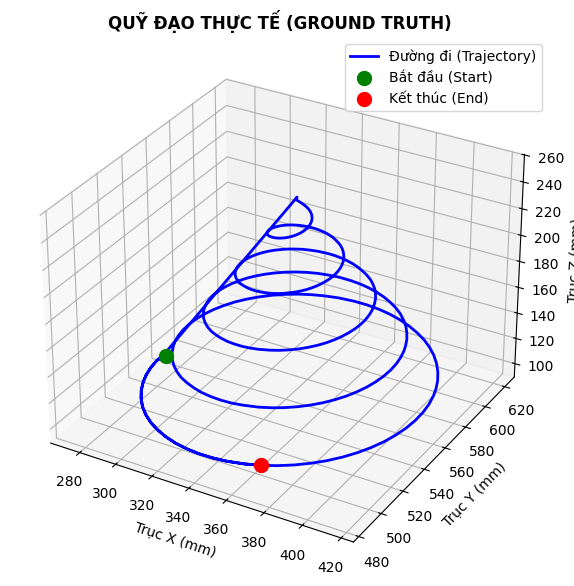

In [ ]:
# ==============================================================================
# SECTION 2: TRỰC QUAN HÓA DỮ LIỆU (GROUND TRUTH TRAJECTORY)
# ==============================================================================
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Vẽ đường quỹ đạo liên tục
ax.plot(gt_pose[:,0]*1000, gt_pose[:,1]*1000, gt_pose[:,2]*1000, 'b-', linewidth=2, label='Đường đi (Trajectory)')

# Đánh dấu điểm bắt đầu và kết thúc
ax.scatter(gt_pose[0,0]*1000, gt_pose[0,1]*1000, gt_pose[0,2]*1000, color='green', s=100, label='Bắt đầu (Start)')
ax.scatter(gt_pose[-1,0]*1000, gt_pose[-1,1]*1000, gt_pose[-1,2]*1000, color='red', s=100, label='Kết thúc (End)')

ax.set_xlabel('Trục X (mm)')
ax.set_ylabel('Trục Y (mm)')
ax.set_zlabel('Trục Z (mm)')
ax.set_title('QUỸ ĐẠO THỰC TẾ (GROUND TRUTH)', fontweight='bold')
ax.legend()
plt.show()

# Section 3: Forward Model

In [ ]:
# ==============================================================================
# SECTION 3: MÔ HÌNH VẬT LÝ (FORWARD MODEL - REGULARIZED DIFFERENTIAL COIL)
# ==============================================================================
# Các ma trận xoay Euler Z-Y-X (đầu vào là độ)
# def rotx(a): return np.array([[1, 0, 0], [0, np.cos(np.radians(a)), -np.sin(np.radians(a))], [0, np.sin(np.radians(a)), np.cos(np.radians(a))]])
# def roty(a): return np.array([[np.cos(np.radians(a)), 0, np.sin(np.radians(a))], [0, 1, 0], [-np.sin(np.radians(a)), 0, np.cos(np.radians(a))]])
# def rotz(a): return np.array([[np.cos(np.radians(a)), -np.sin(np.radians(a)), 0], [np.sin(np.radians(a)), np.cos(np.radians(a)), 0], [0, 0, 1]])

# def forwardModelvisai_dio(params, sys, rx_idx):
#     """
#     Tính tín hiệu EMF với Mô hình Vi sai Điều chuẩn (Regularized Dipole).
#     Sử dụng (r^2 + R^2)^2.5 làm mẫu số để triệt tiêu Singularity.
#     """
#     pos_rx = params[0:3]
#     roll, pitch, yaw = params[3:6]

#     # Ma trận xoay của viên nang và Vector định hướng trục RX
#     RCE = rotz(yaw) @ roty(pitch) @ rotx(roll)
#     if rx_idx == 0: RXk = RCE @ np.array([1, 0, 0])
#     elif rx_idx == 1: RXk = RCE @ np.array([0, 0, 1])
#     else: RXk = RCE @ np.array([0, 1, 0])

#     R2 = sys.R**2  # Bình phương bán kính TX (Hệ số chặn vật lý)
#     Atx = np.pi * R2
#     emf_out = np.zeros(3)

#     for i in range(3):
#         pos_tx = sys.TX_positions[0:3, i]
#         roll_tx, pitch_tx, yaw_tx = sys.TX_positions[3:6, i]

#         # Momen từ của TX
#         Rtx = rotz(yaw_tx) @ roty(pitch_tx) @ rotx(roll_tx)
#         m_vec = (sys.Ntx * sys.I[i]) * Atx * (Rtx @ np.array([0, 0, 1]))

#         # Vector khoảng cách từ tâm TX đến 2 nửa cuộn vi sai (cách nhau d/2)
#         r_plus = (pos_rx + (sys.d_diff / 2) * RXk) - pos_tx
#         r_minus = (pos_rx - (sys.d_diff / 2) * RXk) - pos_tx

#         # Tính từ trường B tại nửa cuộn thứ nhất (B_plus)
#         rp_2 = np.dot(r_plus, r_plus)
#         denom_p = (rp_2 + R2)**2.5  # <--- BÍ QUYẾT TRIỆT TIÊU SINGULARITY
#         B_plus = (sys.mu0 / (4 * np.pi)) * (3 * np.dot(m_vec, r_plus) * r_plus - (rp_2 + R2) * m_vec) / denom_p

#         # Tính từ trường B tại nửa cuộn thứ hai (B_minus)
#         rm_2 = np.dot(r_minus, r_minus)
#         denom_m = (rm_2 + R2)**2.5
#         B_minus = (sys.mu0 / (4 * np.pi)) * (3 * np.dot(m_vec, r_minus) * r_minus - (rm_2 + R2) * m_vec) / denom_m

#         # Bảo toàn bản chất vi sai: Cường độ là sự chênh lệch B chiếu lên trục thu
#         delta_B = np.dot(B_plus - B_minus, RXk)

#         # Công thức tính suất điện động (Scale Factor K sẽ được nhân sau trong Optimizer)
#         emf_out[i] = 2 * np.pi * sys.f[i] * np.abs(delta_B)

#     return emf_out

# ==============================================================================
# SECTION 3: MÔ HÌNH VẬT LÝ - TỪ TRƯỜNG TẠI TÂM VIÊN NANG (KHÔNG TRỪ HAI ĐIỂM)
#   EMF = 2*pi*f * | B(tâm) . n_k |     (B = dipole chuẩn, dùng r_hat, mẫu số r^3)
# ==============================================================================
# Các ma trận xoay Euler Z-Y-X (đầu vào là độ)
def rotx(a): return np.array([[1, 0, 0], [0, np.cos(np.radians(a)), -np.sin(np.radians(a))], [0, np.sin(np.radians(a)), np.cos(np.radians(a))]])
def roty(a): return np.array([[np.cos(np.radians(a)), 0, np.sin(np.radians(a))], [0, 1, 0], [-np.sin(np.radians(a)), 0, np.cos(np.radians(a))]])
def rotz(a): return np.array([[np.cos(np.radians(a)), -np.sin(np.radians(a)), 0], [np.sin(np.radians(a)), np.cos(np.radians(a)), 0], [0, 0, 1]])

def _cap_matrix(sys):
    """(v4) Ma trận xoay cố định của khung viên nang so với hệ GT, từ sys.cap_rot = (roll, pitch, yaw) độ."""
    a = getattr(sys, 'cap_rot', np.zeros(3))
    return rotz(a[2]) @ roty(a[1]) @ rotx(a[0])

def _rx_axis(RCE, rx_idx):
    """Trục cuộn thu theo quy ước RX1->x, RX2->z, RX3->y (rx_idx = 0,1,2)."""
    return RCE @ np.array([[1, 0, 0], [0, 0, 1], [0, 1, 0]], float)[rx_idx]

def _dipole_B(r_vec, m_vec, mu0):
    r_mag = np.linalg.norm(r_vec); r_hat = r_vec / r_mag
    return (mu0 / (4 * np.pi)) * (3 * np.dot(m_vec, r_hat) * r_hat - m_vec) / r_mag**3

def forwardModelvisai_dio(params, sys, rx_idx):
    """
    (v3) Mô hình theo TỪNG cuộn thu, chọn bằng sys.RX_MODE[rx_idx]:
      'center': EMF = 2*pi*f*|B(tâm).n|                      (RX1, RX3)
      'diff'  : EMF = 2*pi*f*|(B(r+) - B(r-)).n|, r± = p ± d/2·n   (RX2)
    rx_idx = 0,1,2 tương ứng RX1, RX2, RX3. Giữ nguyên tên hàm và chữ ký.
    """
    if rx_idx not in (0, 1, 2):
        raise ValueError(f"rx_idx không hợp lệ: {rx_idx} (chỉ nhận 0,1,2)")

    pos_rx = params[0:3]
    roll, pitch, yaw = params[3:6]
    # RXk = _rx_axis(rotz(yaw) @ roty(pitch) @ rotx(roll), rx_idx)                        # (v3, không có xoay cố định)
    RXk = _rx_axis(rotz(yaw) @ roty(pitch) @ rotx(roll) @ _cap_matrix(sys), rx_idx)       # (v4)

    Atx = np.pi * (sys.R**2)
    emf_out = np.zeros(3)
    for i in range(3):
        pos_tx = sys.TX_positions[0:3, i]
        roll_tx, pitch_tx, yaw_tx = sys.TX_positions[3:6, i]
        Rtx = rotz(yaw_tx) @ roty(pitch_tx) @ rotx(roll_tx)
        m_vec = (sys.Ntx * sys.I[i]) * Atx * (Rtx @ np.array([0, 0, 1]))

        if sys.RX_MODE[rx_idx] == 'diff':
            h = sys.d_diff_rx[rx_idx] / 2
            dB = _dipole_B(pos_rx + h * RXk - pos_tx, m_vec, sys.mu0) - _dipole_B(pos_rx - h * RXk - pos_tx, m_vec, sys.mu0)
            emf_out[i] = 2 * np.pi * sys.f[i] * np.abs(np.dot(dB, RXk))
        else:
            emf_out[i] = 2 * np.pi * sys.f[i] * np.abs(np.dot(_dipole_B(pos_rx - pos_tx, m_vec, sys.mu0), RXk))
    return emf_out

# (BẢN v2 - KHÔNG DÙNG) Tất cả RX dùng từ trường tại tâm viên nang
# def forwardModelvisai_dio(params, sys, rx_idx):
#     """
#     rx_idx = 0,1,2 tương ứng RX1, RX2, RX3.
#     Tính EMF từ từ trường dipole TẠI TÂM viên nang rồi chiếu lên trục cuộn thu.
#     (Giữ nguyên tên hàm và chữ ký để Section 4 và 5 không cần sửa. sys.d_diff KHÔNG còn được dùng.)
#     """
#     if rx_idx not in (0, 1, 2):
#         raise ValueError(f"rx_idx không hợp lệ: {rx_idx} (chỉ nhận 0,1,2)")
#
#     pos_rx = params[0:3]
#     roll, pitch, yaw = params[3:6]
#
#     # Ma trận xoay của viên nang và Vector định hướng trục RX
#     RCE = rotz(yaw) @ roty(pitch) @ rotx(roll)
#     if rx_idx == 0: RXk = RCE @ np.array([1, 0, 0])
#     elif rx_idx == 1: RXk = RCE @ np.array([0, 0, 1])
#     else: RXk = RCE @ np.array([0, 1, 0])
#
#     Atx = np.pi * (sys.R**2)
#     emf_out = np.zeros(3)
#
#     for i in range(3):
#         pos_tx = sys.TX_positions[0:3, i]
#         roll_tx, pitch_tx, yaw_tx = sys.TX_positions[3:6, i]
#
#         # Momen từ của TX
#         Rtx = rotz(yaw_tx) @ roty(pitch_tx) @ rotx(roll_tx)
#         m_vec = (sys.Ntx * sys.I[i]) * Atx * (Rtx @ np.array([0, 0, 1]))
#
#         # Từ trường dipole tại TÂM viên nang
#         r_vec = pos_rx - pos_tx
#         r_mag = np.linalg.norm(r_vec)
#         r_hat = r_vec / r_mag
#         B_center = (sys.mu0 / (4 * np.pi)) * (3 * np.dot(m_vec, r_hat) * r_hat - m_vec) / r_mag**3
#
#         # Chiếu lên trục cuộn thu (không trừ hai điểm)
#         emf_out[i] = 2 * np.pi * sys.f[i] * np.abs(np.dot(B_center, RXk))
#
#     return emf_out
#

# ------------------------------------------------------------------------------
# BẢN VECTOR HOÁ (cùng công thức, tính N mẫu cùng lúc cho 1 TX) - dùng trong Section 4 cho nhanh
# ------------------------------------------------------------------------------
_AXES = np.array([[1, 0, 0], [0, 0, 1], [0, 1, 0]], float)   # RX1->x, RX2->z, RX3->y

def _R_batch(p):
    r, pt, y = np.radians(p[:, 3]), np.radians(p[:, 4]), np.radians(p[:, 5])
    cr, sr, cp, sp, cy, sy = np.cos(r), np.sin(r), np.cos(pt), np.sin(pt), np.cos(y), np.sin(y)
    R = np.zeros((len(p), 3, 3))
    R[:, 0, 0] = cy*cp; R[:, 0, 1] = cy*sp*sr - sy*cr; R[:, 0, 2] = cy*sp*cr + sy*sr
    R[:, 1, 0] = sy*cp; R[:, 1, 1] = sy*sp*sr + cy*cr; R[:, 1, 2] = sy*sp*cr - cy*sr
    R[:, 2, 0] = -sp;   R[:, 2, 1] = cp*sr;            R[:, 2, 2] = cp*cr
    return R

def emf_center_batch(poses, sys, rx_idx, tx_idx):
    """EMF mô hình tại TÂM viên nang (chưa nhân K) cho N pose, 1 TX. Khớp forwardModelvisai_dio."""
    # n = _R_batch(poses) @ _AXES[rx_idx]                                   # (v3)
    n = _R_batch(poses) @ (_cap_matrix(sys) @ _AXES[rx_idx])                 # (v4: có xoay cố định)
    c = sys.TX_positions[0:3, tx_idx]
    a, b, g = sys.TX_positions[3:6, tx_idx]
    m = sys.Ntx * sys.I[tx_idx] * np.pi * sys.R**2 * (rotz(g) @ roty(b) @ rotx(a) @ np.array([0, 0, 1.]))
    r = poses[:, :3] - c
    rm = np.linalg.norm(r, axis=1)[:, None]; rh = r / rm
    B = sys.mu0 / (4*np.pi) * (3*np.sum(m*rh, axis=1)[:, None]*rh - m) / rm**3
    return 2*np.pi*sys.f[tx_idx] * np.abs(np.einsum('ij,ij->i', B, n))

def emf_diff_batch(poses, sys, rx_idx, tx_idx):
    """(v3) EMF vi sai hai điểm (chưa nhân K) cho N pose, 1 TX. Khớp forwardModelvisai_dio nhánh 'diff'."""
    # n = _R_batch(poses) @ _AXES[rx_idx]                                   # (v3)
    n = _R_batch(poses) @ (_cap_matrix(sys) @ _AXES[rx_idx])                 # (v4: có xoay cố định)
    c = sys.TX_positions[0:3, tx_idx]
    a, b, g = sys.TX_positions[3:6, tx_idx]
    m = sys.Ntx * sys.I[tx_idx] * np.pi * sys.R**2 * (rotz(g) @ roty(b) @ rotx(a) @ np.array([0, 0, 1.]))
    h = sys.d_diff_rx[rx_idx] / 2
    def Bf(P):
        r = P - c; rm = np.linalg.norm(r, axis=1)[:, None]; rh = r / rm
        return sys.mu0 / (4*np.pi) * (3*np.sum(m*rh, axis=1)[:, None]*rh - m) / rm**3
    dB = Bf(poses[:, :3] + h*n) - Bf(poses[:, :3] - h*n)
    return 2*np.pi*sys.f[tx_idx] * np.abs(np.einsum('ij,ij->i', dB, n))

def emf_rx_batch(poses, sys, rx_idx, tx_idx):
    """(v3) Chọn mô hình theo sys.RX_MODE[rx_idx]. Dùng trong Section 4."""
    if sys.RX_MODE[rx_idx] == 'diff':
        return emf_diff_batch(poses, sys, rx_idx, tx_idx)
    return emf_center_batch(poses, sys, rx_idx, tx_idx)

# ==============================================================================
# (BẢN CŨ - KHÔNG DÙNG) Vi sai hai điểm: B(r+) - B(r-)
# ==============================================================================
# def forwardModelvisai_dio(params, sys, rx_idx):
#     """
#     Tính tín hiệu EMF với Mô hình Điểm từ lý tưởng nguyên thủy.
#     Dùng vector đơn vị r_hat. Mẫu số là r^3, sẽ gây lỗi nếu r -> 0.
#     """
#     pos_rx = params[0:3]
#     roll, pitch, yaw = params[3:6]
#
#     # Ma trận xoay của viên nang và Vector định hướng trục RX
#     RCE = rotz(yaw) @ roty(pitch) @ rotx(roll)
#     if rx_idx == 0: RXk = RCE @ np.array([1, 0, 0])
#     elif rx_idx == 1: RXk = RCE @ np.array([0, 0, 1])
#     else: RXk = RCE @ np.array([0, 1, 0])
#
#     Atx = np.pi * (sys.R**2)
#     emf_out = np.zeros(3)
#
#     for i in range(3):
#         pos_tx = sys.TX_positions[0:3, i]
#         roll_tx, pitch_tx, yaw_tx = sys.TX_positions[3:6, i]
#
#         # Momen từ của TX
#         Rtx = rotz(yaw_tx) @ roty(pitch_tx) @ rotx(roll_tx)
#         m_vec = (sys.Ntx * sys.I[i]) * Atx * (Rtx @ np.array([0, 0, 1]))
#
#         # Vector khoảng cách từ tâm TX đến 2 nửa cuộn vi sai
#         r_plus = (pos_rx + (sys.d_diff / 2) * RXk) - pos_tx
#         r_minus = (pos_rx - (sys.d_diff / 2) * RXk) - pos_tx
#
#         # ======================================================================
#         # MÔ HÌNH DIPOLE GỐC: TỬ SỐ DÙNG r_hat, MẪU SỐ LÀ r^3
#         # ======================================================================
#
#         # --- Tại nửa cuộn thứ nhất (B_plus) ---
#         r_mag_p = np.linalg.norm(r_plus)             # Độ lớn |r|
#         r_hat_p = r_plus / r_mag_p                   # Vector đơn vị r_hat
#         denom_p = r_mag_p**3                         # Mẫu số gốc: r^3 (CHỖ NÀY GÂY KẸT)
#         B_plus = (sys.mu0 / (4 * np.pi)) * (3 * np.dot(m_vec, r_hat_p) * r_hat_p - m_vec) / denom_p
#
#         # --- Tại nửa cuộn thứ hai (B_minus) ---
#         r_mag_m = np.linalg.norm(r_minus)            # Độ lớn |r|
#         r_hat_m = r_minus / r_mag_m                  # Vector đơn vị r_hat
#         denom_m = r_mag_m**3                         # Mẫu số gốc: r^3 (CHỖ NÀY GÂY KẸT)
#         B_minus = (sys.mu0 / (4 * np.pi)) * (3 * np.dot(m_vec, r_hat_m) * r_hat_m - m_vec) / denom_m
#
#         # ======================================================================
#
#         # Bảo toàn bản chất vi sai: Cường độ là sự chênh lệch B chiếu lên trục thu
#         delta_B = np.dot(B_plus - B_minus, RXk)
#
#         # Công thức tính suất điện động
#         emf_out[i] = 2 * np.pi * sys.f[i] * np.abs(delta_B)
#
#     return emf_out

# Section 4: Thuật toán tối ưu (dùng thuật toán least_square)

In [ ]:
# # ==============================================================================
# # SECTION 4: THUẬT TOÁN TỐI ƯU HIỆU CHUẨN (AUTO-CALIBRATION LSQNONLIN)
# # ==============================================================================
# def calib_cost_func(x_opt, gt_pose_data, emf_meas_data, sys, tx_idx, nRx):
#     """ Hàm tính sai số (Residuals) để tối ưu vị trí 3 TX và Hệ số bù trừ K """
#     sys_local = copy.deepcopy(sys)
#     sys_local.TX_positions[:, tx_idx] = x_opt[0:6]
#     K = x_opt[6 : 6+nRx]

#     N = gt_pose_data.shape[0]
#     F = np.zeros(N * nRx)

#     for j in range(nRx):
#         for i in range(N):
#             # Tín hiệu lý thuyết
#             emf_model_all = forwardModelvisai_dio(gt_pose_data[i, :], sys_local, j)
#             emf_model = K[j] * emf_model_all[tx_idx]

#             # Tín hiệu thực tế & Sai số tuyệt đối
#             emf_meas_val = emf_meas_data[i, tx_idx + 3 * j]
#             F[j * N + i] = (emf_model - emf_meas_val)
#     return F

# # Khởi tạo bản sao để chứa cấu hình đã hiệu chuẩn
# sys_post = copy.deepcopy(sys_pre)
# K_post = np.zeros((3, 3))

# # Giá trị K_mồi = (Số vòng RX * Diện tích). Thuật toán sẽ tối ưu từ con số này.
# k_guess = np.array([sys_pre.Nrx * sys_pre.AK[i] for i in range(3)])

# print("🚀 BẮT ĐẦU HIỆU CHUẨN (CALIBRATION) TỪNG CUỘN TX...")
# for tx_idx in range(3):
#     print(f"\nĐang chạy thuật toán Trust Region Reflective (TRF) cho TX{tx_idx + 1}...")
#     x0 = np.concatenate([sys_pre.TX_positions[:, tx_idx], k_guess])

#     # Hộp giới hạn bao trọn không gian (Tọa độ y mở đến 0.9m) và mở khóa hệ số K (1e7)
#     lb = np.array([0.1, 0.3, 0.0, -180, -180, -180,   0.0,   0.0,   0.0])
#     ub = np.array([0.6, 0.9, 0.3,  180,  180,  180, 1e7, 1e7, 1e7])

#     # scipy.least_squares (Tương đương lsqnonlin của MATLAB)
#     res = least_squares(
#         calib_cost_func, x0, bounds=(lb, ub), method='trf',
#         x_scale='jac',  # <--- CRUCIAL FIX: Tự cân bằng Jacobian giúp thoát khỏi Local Minima
#         args=(gt_pose, emf_meas, sys_pre, tx_idx, 3),
#         ftol=1e-8, xtol=1e-8, gtol=1e-8, max_nfev=10000
#     )

#     # Cập nhật kết quả tự động thay vì Copy-Paste
#     sys_post.TX_positions[:, tx_idx] = res.x[0:6]
#     K_post[:, tx_idx] = res.x[6:9]
#     print(f"✅ TX{tx_idx + 1} Hoàn tất. Vector K = {np.round(K_post[:, tx_idx], 3)}")

#     #IN RA BỘ SỐ X_OPT_ALL
# print("\n=== BỘ SỐ x_opt_all TỔNG HỢP ===")
# print("TX      x        y        z      roll     pitch     yaw       K1       K2       K3")
# for i in range(3):
#     tx_params = sys_post.TX_positions[:, i]
#     k_params = K_post[:, i]
#     # Nối tọa độ và K thành mảng 9 số
#     x_opt_row = np.concatenate([tx_params, k_params])
#     # Định dạng in ra giống hệt fprintf của MATLAB
#     row_str = f"TX{i+1}: " + "".join([f"{val:8.5f} " for val in x_opt_row])
#     print(row_str)

# ==============================================================================
# SECTION 4: THUẬT TOÁN HIỆU CHUẨN - PHIÊN BẢN DEVIATION (TÌM ĐỘ LỆCH)
#   Cải tiến: (1) K giải dạng đóng  (2) multi-start  (3) chỉ lệch roll/pitch, yaw cố định
#             (4) cho phép lệch vị trí ±3 cm  (5) trọng số cân bằng cận trường/xa trường
#   => hướng trục TX lệch tối đa ≈ √2 · MAX_ROLL_PITCH ≈ 5°
# ==============================================================================
import copy
import numpy as np
from scipy.optimize import least_squares

# ---- CẤU HÌNH RÀNG BUỘC ĐỘ LỆCH (thứ tự: dx, dy, dz, droll, dpitch, dyaw) ----
MAX_ROLL_PITCH = 3.5                                   # độ (hai góc lệch tối đa; yaw cố định)
DEV_FREE = np.array([True, True, True, True, True, False])         # biến nào được phép lệch (yaw cố định)
DEV_LIM  = np.array([0.03, 0.03, 0.03, MAX_ROLL_PITCH, MAX_ROLL_PITCH, 0.0])   # giới hạn ± (m, độ)
EPS_W = 1.0     # sàn nhiễu (đơn vị EMF) cho trọng số 1/(|EMF đo| + EPS_W): cân bằng cận trường và xa trường
                # EPS_W = None  -> sai số tuyệt đối (cận trường chi phối)
USE_CAP_ROT = True                                     # (v4) ước lượng xoay cố định của viên nang (chung 3 TX)
CAP_ROT_LIM = 30.0                                     # độ, giới hạn ± cho mỗi góc xoay cố định
N_STARTS_CAP = 12                                      # số điểm khởi tạo cho bước 0
N_STARTS = 14                                          # số điểm khởi tạo (điểm 0 = không lệch)
# Muốn chỉ lệch góc (vị trí cố định): đặt DEV_FREE[0:3] = False.

def calib_cost_func_dev(delta_free, gt_pose_data, emf_meas_data, sys, tx_idx, nRx, return_K=False):
    """
    delta_free: chỉ gồm các biến ĐƯỢC PHÉP LỆCH (theo DEV_FREE), là ĐỘ LỆCH so với tọa độ gốc trong sys.
    Hệ số K của từng RX KHÔNG còn là biến tối ưu: với mỗi độ lệch, K được tính dạng đóng
    (bình phương tối thiểu có trọng số) nên không còn phụ thuộc vào K khởi tạo.
    """
    delta = np.zeros(6)
    delta[np.where(DEV_FREE)[0]] = delta_free

    sys_local = copy.copy(sys)
    sys_local.TX_positions = sys.TX_positions.copy()
    # 1. CỘNG ĐỘ LỆCH VÀO TỌA ĐỘ GỐC (thay vì gán đè)
    sys_local.TX_positions[:, tx_idx] = sys.TX_positions[:, tx_idx] + delta

    # 2. Tín hiệu lý thuyết (chưa nhân K) và tín hiệu đo, cho cả nRx cuộn thu
    # M = np.column_stack([emf_center_batch(gt_pose_data, sys_local, j, tx_idx) for j in range(nRx)])   # (v2) cả 3 RX dùng tâm viên nang
    M = np.column_stack([emf_rx_batch(gt_pose_data, sys_local, j, tx_idx) for j in range(nRx)])       # (v3) theo sys.RX_MODE
    Y = np.column_stack([emf_meas_data[:, tx_idx + 3 * j] for j in range(nRx)])

    # 3. Trọng số: mẫu có tín hiệu lớn (cận trường) không lấn át mẫu tín hiệu nhỏ (xa trường)
    W = np.ones_like(Y) if EPS_W is None else 1.0 / (np.abs(Y) + EPS_W)

    # 4. K tối ưu dạng đóng (bình phương tối thiểu có trọng số) cho từng RX
    K = np.sum(W**2 * M * Y, axis=0) / np.sum(W**2 * M * M, axis=0)
    if return_K:
        return K

    # 5. Sai lệch có trọng số (mô hình - đo), gồm N*nRx phần tử
    return (W * (K * M - Y)).ravel()

def _tx_axis(euler):
    """Hướng trục dipole của TX từ (roll, pitch, yaw)."""
    return rotz(euler[2]) @ roty(euler[1]) @ rotx(euler[0]) @ np.array([0, 0, 1.0])

# ==============================================================================
# QUÁ TRÌNH KHỞI CHẠY TỐI ƯU (DEVIATION)
# ==============================================================================

# Ép kiểu dữ liệu (Nếu đang là Pandas DataFrame)
if hasattr(gt_pose, 'to_numpy'):
    gt_pose = gt_pose.to_numpy()
if hasattr(emf_meas, 'to_numpy'):
    emf_meas = emf_meas.to_numpy()

sys_post = copy.deepcopy(sys_pre)
K_post = np.zeros((3, 3))

# K_mồi an toàn (chỉ để đối chiếu; K giờ được giải dạng đóng nên không dùng làm điểm xuất phát)
try:
    k_guess = np.array([sys_pre.Nrx * sys_pre.AK[i] for i in range(3)])
except AttributeError:
    k_guess = np.array([sys_pre.Nrx * sys_pre.Arx] * 3)

print("🚀 BẮT ĐẦU HIỆU CHUẨN (DEVIATION METHOD)...")

# ------------------------------------------------------------------------------
# (v4) BƯỚC 0: ước lượng XOAY CỐ ĐỊNH của viên nang (3 góc, chung cho cả 3 TX), đồng thời với độ lệch 3 TX.
#      Dữ liệu không có xoay (GT góc = 0) nên lỗi này không phân biệt được với TX nếu fit riêng từng TX.
# ------------------------------------------------------------------------------
if USE_CAP_ROT:
    _nfree = int(DEV_FREE.sum()); _idx = np.where(DEV_FREE)[0]
    _lb = np.r_[[-CAP_ROT_LIM] * 3, np.tile(-DEV_LIM[_idx], 3)]
    _ub = -_lb
    def _joint_cost(xj):
        sys_t = copy.copy(sys_pre); sys_t.cap_rot = xj[0:3]
        return np.concatenate([calib_cost_func_dev(xj[3 + _nfree*t : 3 + _nfree*(t+1)], gt_pose, emf_meas, sys_t, t, 3) for t in range(3)])
    _rng0 = np.random.default_rng(1); _best0 = None
    for s0 in range(N_STARTS_CAP):
        x0j = np.zeros(len(_lb)) if s0 == 0 else _rng0.uniform(_lb, _ub) * 0.6
        r0 = least_squares(_joint_cost, np.clip(x0j, _lb + 1e-9, _ub - 1e-9), bounds=(_lb, _ub), method='trf',
                           x_scale=np.r_[[5.0]*3, np.tile(np.array([0.02, 0.02, 0.02, 3.0, 3.0, 3.0])[_idx], 3)], max_nfev=80)
        if _best0 is None or r0.cost < _best0.cost: _best0 = r0
    sys_pre.cap_rot = _best0.x[0:3].copy()
    print(f"   Bước 0: xoay cố định viên nang (roll, pitch, yaw) = {np.round(sys_pre.cap_rot, 2)} độ  (cost chung = {_best0.cost:.1f})")
sys_post.cap_rot = sys_pre.cap_rot.copy()

idx_free = np.where(DEV_FREE)[0]
lb_dev = -DEV_LIM[idx_free]
ub_dev = DEV_LIM[idx_free]
rng = np.random.default_rng(0)

for tx_idx in range(3):
    print(f"\nĐang chạy thuật toán TRF cho TX{tx_idx + 1}...")

    # 1. MULTI-START: điểm 0 là "không lệch" (độ lệch = 0), các điểm còn lại ngẫu nhiên trong hộp cho phép
    best = None
    for s in range(N_STARTS):
        x0_dev = np.zeros(len(idx_free)) if s == 0 else rng.uniform(lb_dev, ub_dev)
        x0_dev = np.clip(x0_dev, lb_dev + 1e-12, ub_dev - 1e-12)

        # 2. KHÓA CHẶT LỒNG KHÔNG GIAN theo DEV_LIM (độ lệch góc tối đa MAX_ROLL_PITCH)
        res = least_squares(
            calib_cost_func_dev, x0_dev, bounds=(lb_dev, ub_dev), method='trf',
            x_scale=np.array([0.02, 0.02, 0.02, 3.0, 3.0, 3.0])[idx_free],
            args=(gt_pose, emf_meas, sys_pre, tx_idx, 3),
            ftol=1e-8, xtol=1e-8, gtol=1e-8, max_nfev=150
        )
        if best is None or res.cost < best.cost:
            best = res

    # 3. GÁN KẾT QUẢ VÀO HỆ THỐNG (Cập nhật lại tọa độ tuyệt đối)
    delta_opt = np.zeros(6)
    delta_opt[idx_free] = best.x
    sys_post.TX_positions[:, tx_idx] = sys_pre.TX_positions[:, tx_idx] + delta_opt
    K_post[:, tx_idx] = calib_cost_func_dev(best.x, gt_pose, emf_meas, sys_pre, tx_idx, 3, return_K=True)

    axis_dev = np.degrees(np.arccos(np.clip(
        _tx_axis(sys_post.TX_positions[3:6, tx_idx]) @ _tx_axis(sys_pre.TX_positions[3:6, tx_idx]), -1, 1)))

    print(f"✅ TX{tx_idx + 1} Hoàn tất.")
    print(f"   Độ lệch (Delta) tìm được: {np.round(delta_opt, 4)}")
    print(f"   Vector K: {np.round(K_post[:, tx_idx], 3)}")
    print(f"   Hướng trục lệch so với cơ khí: {axis_dev:.2f}°  (cost = {best.cost:.1f})")

# ==============================================================================
# IN BẢNG KẾT QUẢ TỔNG HỢP (TUYỆT ĐỐI)
# ==============================================================================
print("\n=== BỘ SỐ x_opt_all TỔNG HỢP (TỌA ĐỘ CUỐI CÙNG SAU KHI CiỘNG LỆCH) ===")
print("TX      x        y        z      roll     pitch    yaw       K1       K2       K3")
for i in range(3):
    tx_params = sys_post.TX_positions[:, i]
    k_params = K_post[:, i]
    x_opt_row = np.concatenate([tx_params, k_params])
    row_str = f"TX{i+1}: " + "".join([f"{val:8.5f} " for val in x_opt_row])
    print(row_str)

# ==============================================================================
# (BẢN DEVIATION CŨ - KHÔNG DÙNG) K là biến tối ưu, khởi tạo K = Nrx*AK, góc ±5° mỗi góc Euler
# ==============================================================================
# # ==============================================================================
# # SECTION 4: THUẬT TOÁN HIỆU CHUẨN - PHIÊN BẢN DEVIATION (TÌM ĐỘ LỆCH)
# # ==============================================================================
# import copy
# import numpy as np
# from scipy.optimize import least_squares
#
# def calib_cost_func_dev(delta_opt, gt_pose_data, emf_meas_data, sys, tx_idx, nRx):
#     """
#     delta_opt (9 biến): [dx, dy, dz, droll, dpitch, dyaw, K1, K2, K3]
#     Trong đó 6 biến đầu là ĐỘ LỆCH, 3 biến sau vẫn là hệ số K tuyệt đối.
#     """
#     sys_local = copy.deepcopy(sys)
#
#     # 1. CỘNG ĐỘ LỆCH VÀO TỌA ĐỘ GỐC (Thay vì gán đè)
#     # Lấy tọa độ thiết kế ban đầu của cuộn TX đang xét
#     pos_original = sys_local.TX_positions[:, tx_idx].copy()
#
#     # Tạo tọa độ mới = Tọa độ gốc + Độ lệch (delta)
#     sys_local.TX_positions[:, tx_idx] = pos_original + delta_opt[0:6]
#
#     # Hệ số K vẫn giữ nguyên bản chất tuyệt đối
#     K = delta_opt[6 : 6+nRx]
#
#     N = gt_pose_data.shape[0]
#     F = np.zeros(N * nRx)
#
#     for j in range(nRx):
#         for i in range(N):
#             # Tín hiệu lý thuyết
#             emf_model_all = forwardModelvisai_dio(gt_pose_data[i, :], sys_local, j)
#             emf_model = K[j] * emf_model_all[tx_idx]
#
#             # Tín hiệu thực tế
#             emf_meas_val = emf_meas_data[i, tx_idx + 3 * j]
#
#             # Sai lệch
#             F[j * N + i] = (emf_model - emf_meas_val)
#
#     return F
#
# # ==============================================================================
# # QUÁ TRÌNH KHỞI CHẠY TỐI ƯU (DEVIATION)
# # ==============================================================================
#
# # Ép kiểu dữ liệu (Nếu đang là Pandas DataFrame)
# if hasattr(gt_pose, 'to_numpy'):
#     gt_pose = gt_pose.to_numpy()
# if hasattr(emf_meas, 'to_numpy'):
#     emf_meas = emf_meas.to_numpy()
#
# sys_post = copy.deepcopy(sys_pre)
# K_post = np.zeros((3, 3))
#
# # K_mồi an toàn
# try:
#     k_guess = np.array([sys_pre.Nrx * sys_pre.AK[i] for i in range(3)])
# except AttributeError:
#     k_guess = np.array([sys_pre.Nrx * sys_pre.Arx] * 3)
#
# print("🚀 BẮT ĐẦU HIỆU CHUẨN (DEVIATION METHOD)...")
#
# for tx_idx in range(3):
#     print(f"\nĐang chạy thuật toán TRF cho TX{tx_idx + 1}...")
#
#     # 1. ĐIỂM XUẤT PHÁT MỚI (x0)
#     # Ban đầu, ta hy vọng độ lệch = 0.
#     # Nên 6 biến đầu (dx, dy, dz, droll, dpitch, dyaw) khởi tạo là 0
#     delta0 = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0])
#     x0_dev = np.concatenate([delta0, k_guess])
#
#     # 2. KHÓA CHẶT LỒNG KHÔNG GIAN (Vũ khí bí mật của phương pháp này)
#     # Giới hạn độ lệch tọa độ: +- 5cm (0.05m)
#     # Giới hạn độ lệch góc: +- 5 độ (Tùy thuộc vào sai số gia công của bạn)
#     # Gain K thì vẫn để từ 0 đến 1e7
#     lb_dev = np.array([-0.05, -0.05, -0.05, -5.0, -5.0, -5.0,   0.0,   0.0,   0.0])
#     ub_dev = np.array([ 0.05,  0.05,  0.05,  5.0,  5.0,  5.0, 1e7, 1e7, 1e7])
#
#     # 3. CHẠY THUẬT TOÁN
#     res = least_squares(
#         calib_cost_func_dev, x0_dev, bounds=(lb_dev, ub_dev), method='trf',
#         x_scale='jac',
#         args=(gt_pose, emf_meas, sys_pre, tx_idx, 3),
#         ftol=1e-8, xtol=1e-8, gtol=1e-8, max_nfev=10000
#     )
#
#     # 4. GÁN KẾT QUẢ VÀO HỆ THỐNG (Cập nhật lại tọa độ tuyệt đối)
#     delta_opt = res.x[0:6]
#     sys_post.TX_positions[:, tx_idx] = sys_pre.TX_positions[:, tx_idx] + delta_opt
#     K_post[:, tx_idx] = res.x[6:9]
#
#     print(f"✅ TX{tx_idx + 1} Hoàn tất.")
#     print(f"   Độ lệch (Delta) tìm được: {np.round(delta_opt, 4)}")
#     print(f"   Vector K: {np.round(K_post[:, tx_idx], 3)}")
#
# # ==============================================================================
# # IN BẢNG KẾT QUẢ TỔNG HỢP (TUYỆT ĐỐI)
# # ==============================================================================
# print("\n=== BỘ SỐ x_opt_all TỔNG HỢP (TỌA ĐỘ CUỐI CÙNG SAU KHI CiỘNG LỆCH) ===")
# print("TX      x        y        z      roll     pitch    yaw       K1       K2       K3")
# for i in range(3):
#     tx_params = sys_post.TX_positions[:, i]
#     k_params = K_post[:, i]
#     x_opt_row = np.concatenate([tx_params, k_params])
#     row_str = f"TX{i+1}: " + "".join([f"{val:8.5f} " for val in x_opt_row])
#     print(row_str)

🚀 BẮT ĐẦU HIỆU CHUẨN (DEVIATION METHOD)...
   Bước 0: xoay cố định viên nang (roll, pitch, yaw) = [-17.57 -11.21  11.72] độ  (cost chung = 55.4)

Đang chạy thuật toán TRF cho TX1...
✅ TX1 Hoàn tất.
   Độ lệch (Delta) tìm được: [ 3.10e-03  3.00e-02 -2.87e-02 -3.50e+00  3.50e+00  0.00e+00]
   Vector K: [ 0.648 18.774  0.642]
   Hướng trục lệch so với cơ khí: 4.88°  (cost = 24.7)

Đang chạy thuật toán TRF cho TX2...
✅ TX2 Hoàn tất.
   Độ lệch (Delta) tìm được: [ 1.12e-02 -3.10e-03 -3.00e-02  3.50e+00  3.50e+00  0.00e+00]
   Vector K: [0.66  6.655 1.392]
   Hướng trục lệch so với cơ khí: 4.95°  (cost = 9.8)

Đang chạy thuật toán TRF cho TX3...
✅ TX3 Hoàn tất.
   Độ lệch (Delta) tìm được: [-1.60e-03 -2.40e-03 -2.08e-02 -3.50e+00 -9.09e-02  0.00e+00]
   Vector K: [0.179 3.117 0.448]
   Hướng trục lệch so với cơ khí: 3.50°  (cost = 20.8)

=== BỘ SỐ x_opt_all TỔNG HỢP (TỌA ĐỘ CUỐI CÙNG SAU KHI CiỘNG LỆCH) ===
TX      x        y        z      roll     pitch    yaw       K1       K2       K3
TX1

# Section 5: Check hiệu chuẩn


🚀 BẮT ĐẦU CHẠY BÀI TOÁN NGƯỢC (INVERSE SOLVER) CHECK SAI SỐ...
🎯 RMSE Vị trí Post-Calib: 20.61 mm


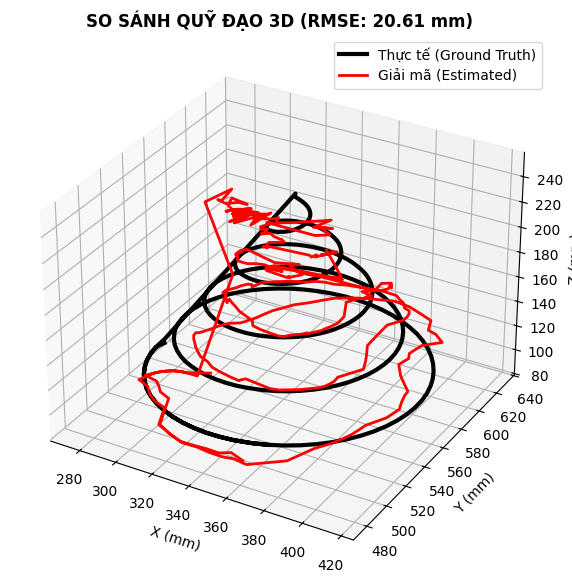

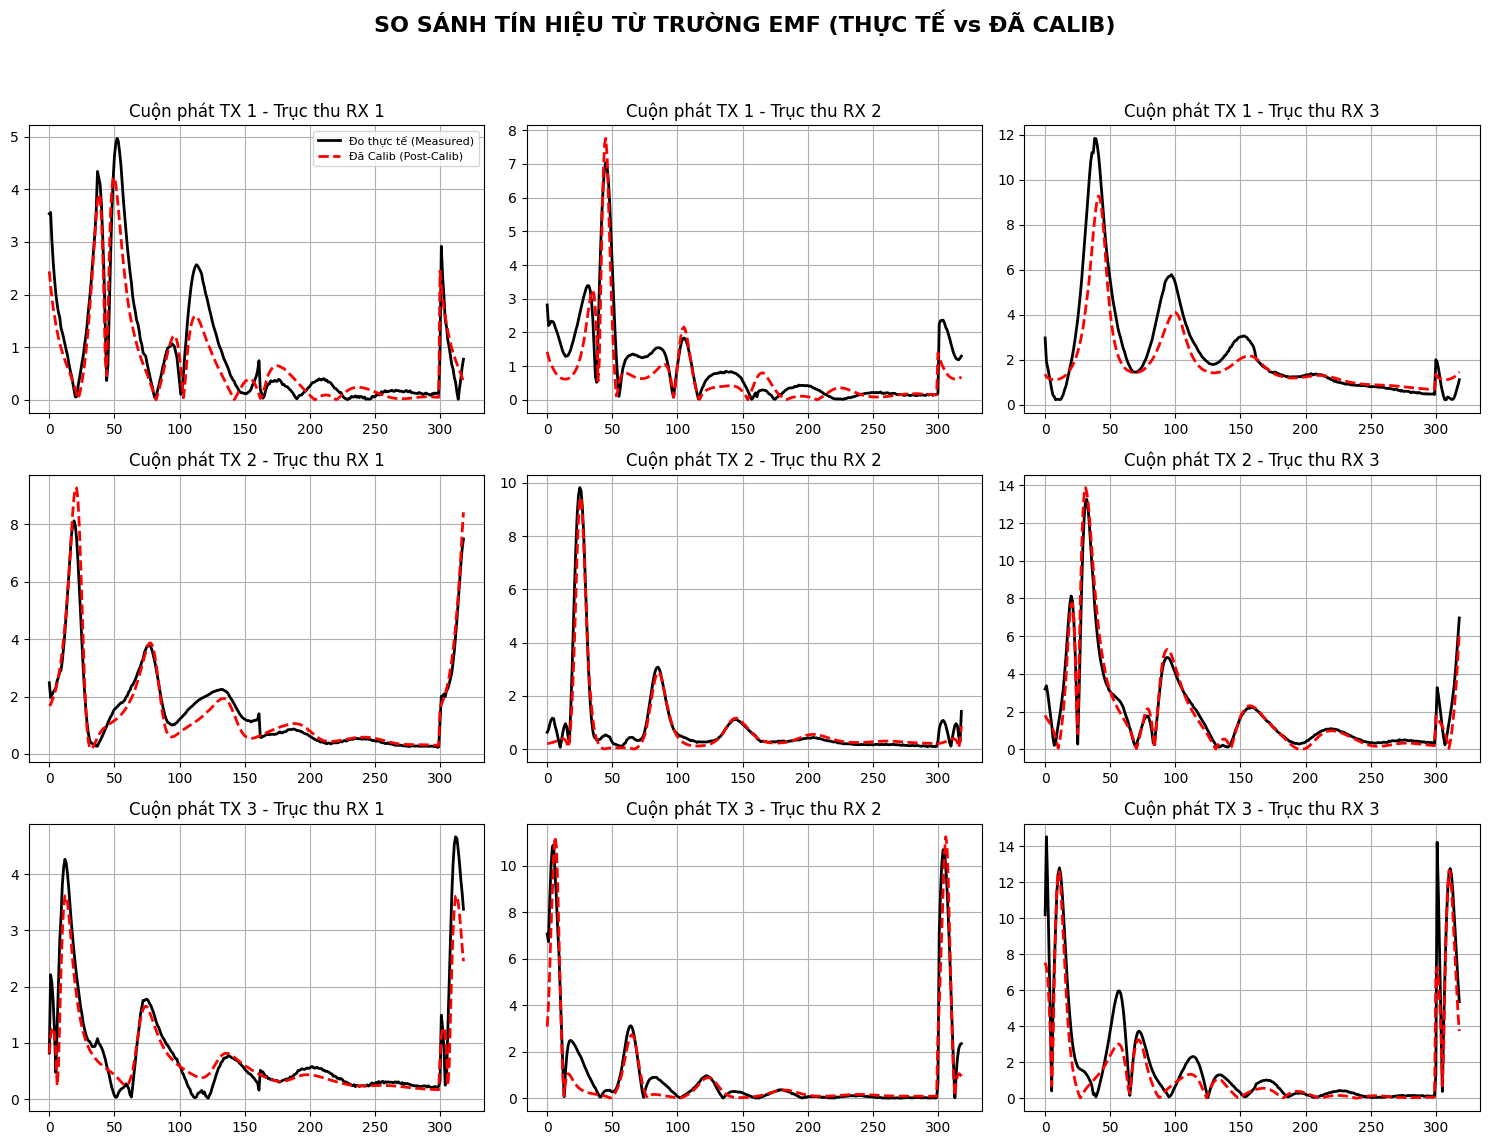

In [ ]:
# ==============================================================================
# SECTION 5: CHECK HIỆU CHUẨN (INVERSE KINEMATICS & VISUALIZATION)
# ==============================================================================
def build_residual_inv(pose, sys, K_matrix, target_emf_single):
    """ Hàm tính sai số cho bài toán dò tìm ngược (Định vị quỹ đạo 6D) """
    res = np.zeros(9)
    for i in range(3):
        emf_raw = forwardModelvisai_dio(pose, sys, i)
        emf_i = K_matrix[i, :] * emf_raw

        idx_start, idx_end = i * 3, i * 3 + 3
        res[idx_start:idx_end] = emf_i - target_emf_single[idx_start:idx_end]
    return res

est_pose_post = np.zeros((N_samples, 6))

print("\n🚀 BẮT ĐẦU CHẠY BÀI TOÁN NGƯỢC (INVERSE SOLVER) CHECK SAI SỐ...")
min_traj = np.min(gt_pose, axis=0)
max_traj = np.max(gt_pose, axis=0)

for i in range(N_samples):
    p0 = gt_pose[i, :].copy()
    p0[0:3] += 0.0001 # Mồi điểm dò tìm quanh quỹ đạo (nhiễu 0.1mm)

    # Hộp giới hạn dò tìm linh hoạt +-10cm và +-10 độ
    lb = np.concatenate([min_traj[0:3] - 0.1, min_traj[3:6] - 10])
    ub = np.concatenate([max_traj[0:3] + 0.1, max_traj[3:6] + 10])

    res = least_squares(
        build_residual_inv, p0, bounds=(lb, ub), method='trf',
        x_scale='jac',
        args=(sys_post, K_post, emf_meas[i, :]),
        ftol=1e-8, xtol=1e-8, gtol=1e-8
    )
    est_pose_post[i, :] = res.x

# 1. ĐÁNH GIÁ SAI SỐ (RMSE)
err_post = np.linalg.norm(est_pose_post[:, 0:3] - gt_pose[:, 0:3], axis=1) * 1000
rmse_post = np.sqrt(np.mean(err_post**2))
print(f"🎯 RMSE Vị trí Post-Calib: {rmse_post:.2f} mm")

# 2. VẼ SO SÁNH QUỸ ĐẠO
fig1 = plt.figure(figsize=(10, 7))
ax1 = fig1.add_subplot(111, projection='3d')
ax1.plot(gt_pose[:,0]*1000, gt_pose[:,1]*1000, gt_pose[:,2]*1000, 'k-', linewidth=3, label='Thực tế (Ground Truth)')
ax1.plot(est_pose_post[:,0]*1000, est_pose_post[:,1]*1000, est_pose_post[:,2]*1000, 'r-', linewidth=2, label='Giải mã (Estimated)')
ax1.set_xlabel('X (mm)'); ax1.set_ylabel('Y (mm)'); ax1.set_zlabel('Z (mm)')
ax1.set_title(f'SO SÁNH QUỸ ĐẠO 3D (RMSE: {rmse_post:.2f} mm)', fontweight='bold')
ax1.legend()
plt.show()

# 3. TÁI TẠO TÍN HIỆU EMF LÝ THUYẾT VÀ VẼ LƯỚI 3x3
emf_post_reconstruct = np.zeros((N_samples, 9))
for i in range(N_samples):
    for rx_idx in range(3):
        emf_raw = forwardModelvisai_dio(gt_pose[i, :], sys_post, rx_idx)
        emf_post_reconstruct[i, rx_idx*3 : rx_idx*3+3] = K_post[rx_idx, :] * emf_raw

fig2, axs = plt.subplots(3, 3, figsize=(15, 12))
fig2.suptitle('SO SÁNH TÍN HIỆU TỪ TRƯỜNG EMF (THỰC TẾ vs ĐÃ CALIB)', fontsize=16, fontweight='bold')

for rx in range(3):
    for tx in range(3):
        idx = tx + 3 * rx
        ax = axs[tx, rx]
        ax.plot(emf_meas[:, idx], 'k', linewidth=2, label='Đo thực tế (Measured)')
        ax.plot(emf_post_reconstruct[:, idx], 'r--', linewidth=2, label='Đã Calib (Post-Calib)')
        ax.set_title(f'Cuộn phát TX {tx+1} - Trục thu RX {rx+1}')
        ax.grid(True)
        if tx == 0 and rx == 0:
            ax.legend(loc='best', fontsize=8)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()